<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Preserve document coverage before selecting text

**What disappears when we keep only long extracted text?** We will use Apache Tika
through VGI to audit a small document manifest, preserve failures and empty text,
and separate physical PDF pages from whole-document fallback rows. Then we will
apply an explicit minimum-character rule and measure the coverage it changes.

Every file is authored for this notebook. The collection contains a four-page PDF,
a DOCX note, an HTML brief, whitespace-only text and a corrupt PDF, plus missing-file
and missing-input cases. OCR is explicitly disabled. This is a text-layer extraction
walkthrough, not a claim that images, tables or document meaning have been recovered.

## Choose a minimum normalized-text length

Start with `MIN_CHARS=40`, then try `150`. Accepted values are integers from 1 to
5000. We normalize runs of whitespace to one space and trim the ends before counting
characters. This is a transparent selection rule, **not** a token budget, language
confidence, relevance score or quality measure. Restart and run all after editing it.

In [1]:
MIN_CHARS = 40

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(MIN_CHARS) is not int or not 1 <= MIN_CHARS <= 5000:
    raise ValueError("MIN_CHARS must be an integer from 1 to 5000.")
outcomes = chunks = coverage = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tika/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tika/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tika/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-tika/notebooks/pyproject.toml.

## Attach the public release

The literal command fetches the v0.4.0 Java worker and verifies its pinned SHA-256
on download and every cached launch. Java 21+ and `uv` are prerequisites. The helper
is included with the notebook; no local worker build is needed. Network access is
needed for initial installation, while these document reads are entirely local.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'tika' (TYPE vgi,LOCATION 'uv run --frozen --project . python release_jar.py Query-farm/vgi-tika v0.4.0 vgi-tika-v0.4.0.jar 4f65055a0c97e7e94a90377bc6b469ee2d955440135e23c049112e12d3affa61');

,Success


## Start with a manifest, then extract the column of paths

`extract_all` takes a relation, selects the document column, and passes through the
chosen ID. A VARCHAR document value is a filesystem path; use BLOB for inline
bytes. A parse error belongs to its input row and does not stop the rest of this
batch. Materialize the results before diagnostics and charts so those steps do not
repeat extraction.

The input intentionally includes a NULL path and a path that does not exist. They
are distinct source conditions even though neither can yield a document body.

In [4]:
%%sql
CREATE TABLE documents AS
SELECT * FROM (VALUES
 ('PDF','assets/field-guide.pdf','Four-page text-layer PDF'),
 ('DOCX','assets/support-note.docx','Two paragraphs; no page metadata'),
 ('HTML','assets/brief.html','Short HTML body'),
 ('SPACE','assets/whitespace.txt','Whitespace only'),
 ('BAD','assets/corrupt.pdf','Deliberately corrupt PDF'),
 ('MISSING','assets/does-not-exist.pdf','Missing file'),
 ('NULL',NULL,'Missing input path')
) t(doc_id,doc_path,fixture_description);
CREATE TABLE extracted_documents AS
SELECT * FROM tika.main.extract_all(
 (SELECT doc_id,doc_path FROM documents ORDER BY doc_id),
 id := 'doc_id',doc_column := 'doc_path',ocr := false);
CREATE TABLE document_audit AS
SELECT d.*,e.mime,e.n_pages,e.content,e.error,
 trim(regexp_replace(e.content,'\s+',' ','g')) AS normalized_text,
 CASE WHEN d.doc_path IS NULL THEN 'Missing input'
      WHEN e.error IS NOT NULL THEN 'Extraction error'
      WHEN e.content IS NULL THEN 'Missing output'
      WHEN length(trim(regexp_replace(e.content,'\s+',' ','g')))=0 THEN 'No extracted text'
      ELSE 'Text available' END AS extraction_state
FROM documents d LEFT JOIN extracted_documents e USING(doc_id);
SELECT doc_id,fixture_description,extraction_state,mime,n_pages,
 length(normalized_text) AS normalized_characters,error
FROM document_audit ORDER BY doc_id;

,doc_id,fixture_description,extraction_state,mime,n_pages,normalized_characters,error
0,BAD,Deliberately corrupt PDF,Extraction error,None,<NA>,<NA>,TikaException: TIKA-198: Illegal IOException f...
1,DOCX,Two paragraphs; no page metadata,Text available,application/vnd.openxmlformats-officedocument....,<NA>,263,None
2,HTML,Short HTML body,Text available,text/html; charset=windows-1252,<NA>,93,None
3,MISSING,Missing file,Extraction error,None,<NA>,<NA>,NoSuchFileException: assets/does-not-exist.pdf
4,NULL,Missing input path,Missing input,None,<NA>,<NA>,missing document column value
5,PDF,Four-page text-layer PDF,Text available,application/pdf,4,434,None
6,SPACE,Whitespace only,No extracted text,text/plain; charset=windows-1252,<NA>,0,None


## Keep the document denominator visible

A successful query is not the same as a successful extraction for every input.
The raw `error` messages remain available above. Missing input, failed extraction,
and successful extraction with no non-whitespace text are separate states. Unknown
body length is NULL, while the whitespace-only document has a known normalized
length of zero. The threshold does not affect this inventory.

In [5]:
%%sql outcomes <<
SELECT extraction_state,count(*) AS documents,
 string_agg(doc_id,', ' ORDER BY doc_id) AS source_ids
FROM document_audit GROUP BY extraction_state ORDER BY documents DESC,extraction_state;

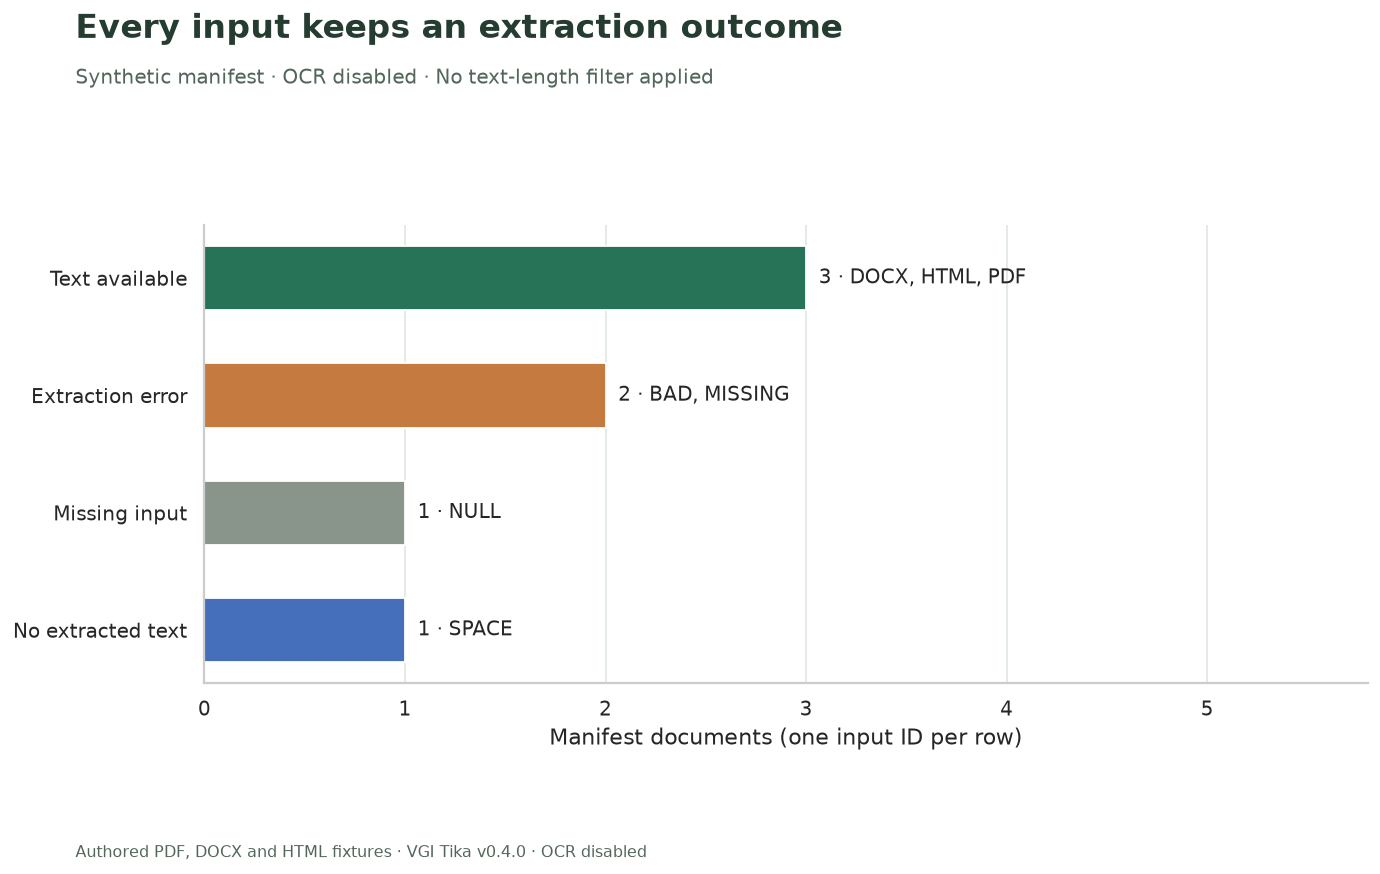

**3 of 7 manifest inputs** have nonempty normalized text. The remaining inputs stay in the audit. A blank body does not prove a document has no visual content; our whitespace-only file is deliberately blank, while a real scanned document might need a different extraction path.

In [6]:
colors = {
    "Text available": "#267358",
    "No extracted text": "#456fba",
    "Extraction error": "#c57b40",
    "Missing input": "#89948b",
    "Missing output": "#a84e4e",
}
fig, ax = plt.subplots(figsize=(11, 6.8))
bars = ax.barh(
    outcomes.extraction_state,
    outcomes.documents,
    color=[colors[x] for x in outcomes.extraction_state],
    height=0.55,
)
ax.bar_label(
    bars,
    labels=[f"{r.documents} · {r.source_ids}" for r in outcomes.itertuples()],
    padding=7,
    fontsize=11,
)
ax.invert_yaxis()
ax.set_xlim(0, int(outcomes.documents.max()) + 2.8)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Manifest documents (one input ID per row)")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Every input keeps an extraction outcome",
    "Synthetic manifest · OCR disabled · No text-length filter applied",
    "01_document_coverage.png",
    bottom=0.12,
)
available = int(outcomes.loc[outcomes.extraction_state == "Text available", "documents"].sum())
prose(
    f"**{available} of {int(outcomes.documents.sum())} manifest inputs** have nonempty normalized text. "
    "The remaining inputs stay in the audit. A blank body does not prove a document has no visual content; "
    "our whitespace-only file is deliberately blank, while a real scanned document might need a different extraction path."
)

## Inspect what a page row actually represents

For this PDF with OCR off, `by_page := true` uses real PDF page boundaries. For
DOCX and HTML, the same option returns the **whole document as one fallback row**.
The returned `page` value is not evidence of a physical page for those formats.
We label the row kind explicitly rather than mixing all rows into a page count.

These are separate, deliberate calls to inspect page behavior for the three
successfully extracted documents. Single-document table functions require literal
paths; `extract_all` is the relation-based interface for a general manifest.
Document metadata accompanies the first PDF page; later empty metadata maps and
NULL language fields do not mean those pages lack a source document.

In [7]:
%%sql
CREATE TABLE extracted_chunks AS
SELECT 'PDF' AS doc_id,'PDF page' AS row_kind,*
FROM tika.main.extract_text('assets/field-guide.pdf',by_page := true,ocr := false)
UNION ALL
SELECT 'DOCX','Whole document',*
FROM tika.main.extract_text('assets/support-note.docx',by_page := true,ocr := false)
UNION ALL
SELECT 'HTML','Whole document',*
FROM tika.main.extract_text('assets/brief.html',by_page := true,ocr := false);
CREATE TABLE chunk_audit AS
SELECT *,trim(regexp_replace(content,'\s+',' ','g')) AS normalized_text,
 length(trim(regexp_replace(content,'\s+',' ','g'))) AS normalized_characters
FROM extracted_chunks;
SELECT doc_id,row_kind,page,n_pages,cardinality(meta) AS metadata_keys,
 normalized_characters,left(normalized_text,70) AS text_preview,error
FROM chunk_audit ORDER BY doc_id,page;

,doc_id,row_kind,page,n_pages,metadata_keys,normalized_characters,text_preview,error
0,DOCX,Whole document,1,<NA>,6,263,Synthetic support note. A document can contain...,None
1,HTML,Whole document,1,<NA>,10,93,Synthetic brief. Check document provenance bef...,None
2,PDF,PDF page,1,4,32,304,Synthetic field guide. Before indexing a docum...,None
3,PDF,PDF page,2,4,0,2,OK,None
4,PDF,PDF page,3,4,0,0,,None
5,PDF,PDF page,4,4,0,126,Synthetic checklist. Confirm the source identi...,None


## Repeated page totals are not additive

Each PDF page row repeats the document's total `n_pages`. Summing that field counts
the total once per emitted page. Use the row count for verified page rows and a
single document-level total for comparison. Unknown page totals on DOCX and HTML
remain NULL; a one-row fallback does not turn them into one-page documents.

In [8]:
%%sql
SELECT doc_id,row_kind,count(*) AS emitted_rows,
 count(DISTINCT page) AS distinct_returned_ordinals,
 max(n_pages) AS reported_document_pages,
 sum(n_pages) AS naive_sum_of_repeated_page_totals
FROM chunk_audit GROUP BY doc_id,row_kind ORDER BY doc_id;

,doc_id,row_kind,emitted_rows,distinct_returned_ordinals,reported_document_pages,naive_sum_of_repeated_page_totals
0,DOCX,Whole document,1,1,<NA>,NaN
1,HTML,Whole document,1,1,<NA>,NaN
2,PDF,PDF page,4,4,4,16.0


## Apply the minimum length while retaining every chunk

A blank PDF page has a normalized character count of zero. The short `OK` page
contains real extracted text but is below the default cutoff. Neither case is an
extraction error. The whole-document rows share the length rule, but their boundary
labels remain different from the PDF page labels.

In [9]:
%%sql chunks <<
SELECT doc_id,row_kind,page,normalized_characters,
 error IS NULL AND normalized_characters>={{ MIN_CHARS }} AS selected
FROM chunk_audit ORDER BY CASE doc_id WHEN 'PDF' THEN 0 WHEN 'DOCX' THEN 1 ELSE 2 END,page;

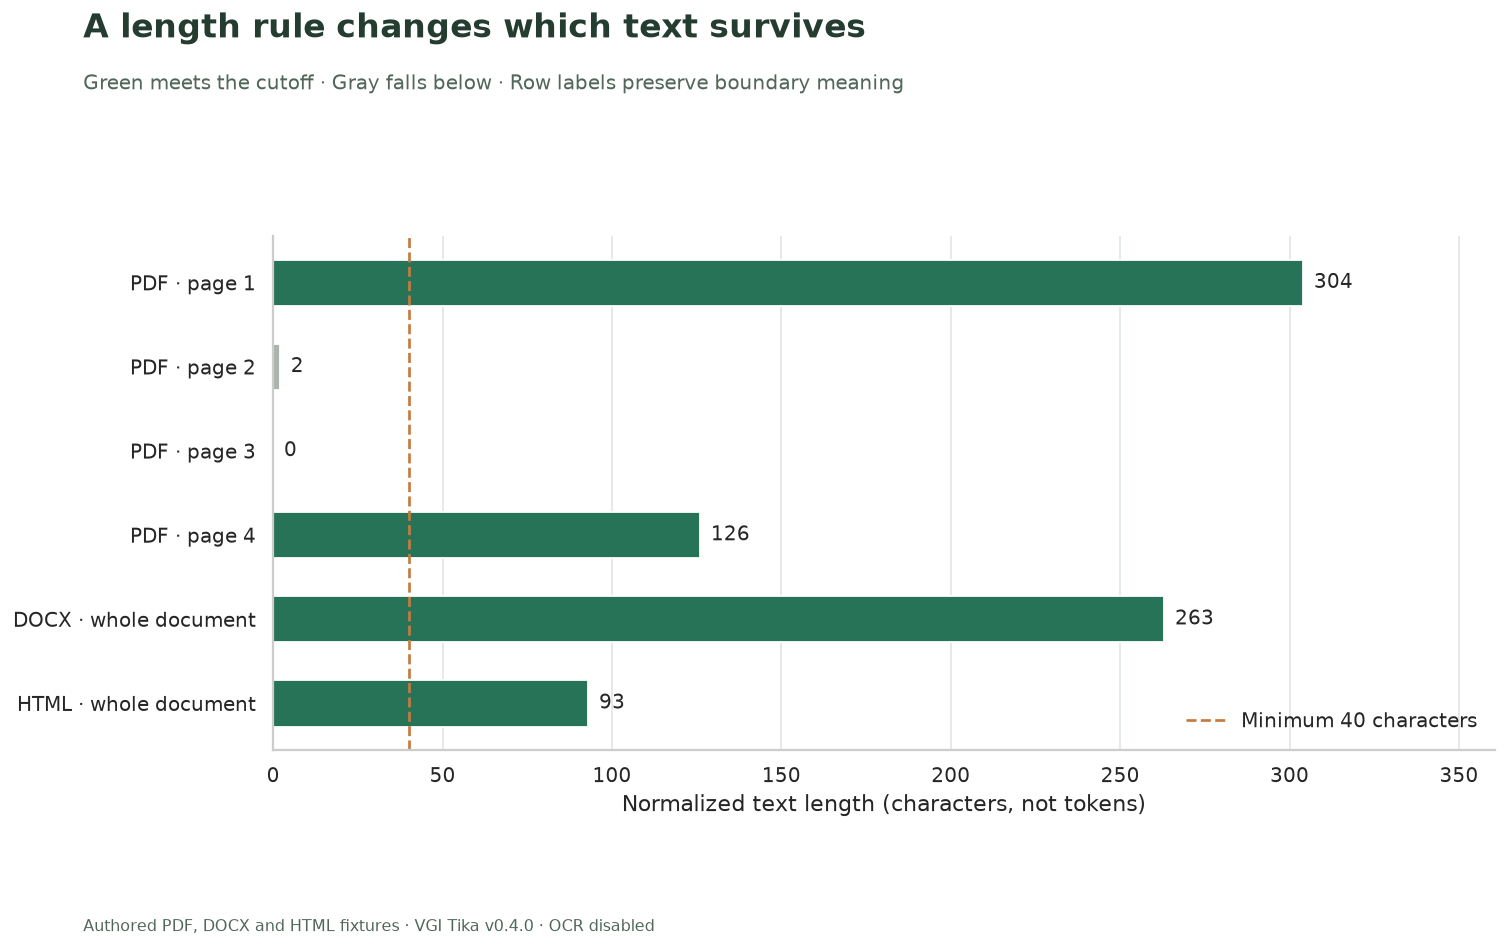

At **40 characters**, **4 of 6 extracted rows** meet the rule. A longer body is not necessarily more useful. The short OK page may matter to a reader even though this policy excludes it.

In [10]:
labels = [
    f"PDF · page {r.page}" if r.row_kind == "PDF page" else f"{r.doc_id} · whole document"
    for r in chunks.itertuples()
]
fig, ax = plt.subplots(figsize=(12, 7.4))
bars = ax.barh(
    labels,
    chunks.normalized_characters,
    color=["#267358" if x else "#aab4ac" for x in chunks.selected],
    height=0.55,
)
ax.bar_label(bars, padding=6, fontsize=11)
ax.axvline(
    MIN_CHARS,
    color="#c57b40",
    linestyle="--",
    linewidth=1.5,
    label=f"Minimum {MIN_CHARS} characters",
)
ax.invert_yaxis()
ax.set_xlim(0, max(int(chunks.normalized_characters.max()), MIN_CHARS) * 1.16 + 8)
ax.set_xlabel("Normalized text length (characters, not tokens)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
finish(
    fig,
    "A length rule changes which text survives",
    "Green meets the cutoff · Gray falls below · Row labels preserve boundary meaning",
    "02_chunk_selection.png",
    bottom=0.12,
)
prose(
    f"At **{MIN_CHARS} characters**, **{int(chunks.selected.sum())} of {len(chunks)} extracted rows** meet the rule. "
    "A longer body is not necessarily more useful. The short OK page may matter to a reader even though this policy excludes it."
)

## Report selected documents separately from selected PDF pages

A document can remain represented even when some of its pages are excluded. Count
distinct source IDs for represented documents and only the `PDF page` rows for
physical page coverage. Keep whole-document fallbacks in their own count.

In [11]:
%%sql coverage <<
WITH selected AS (
 SELECT * FROM chunk_audit WHERE error IS NULL AND normalized_characters>={{ MIN_CHARS }}
)
SELECT (SELECT count(*) FROM documents) AS manifest_documents,
 (SELECT count(*) FROM document_audit WHERE extraction_state='Text available') AS documents_with_text,
 (SELECT count(DISTINCT doc_id) FROM chunk_audit) AS documents_in_chunk_audit,
 count(DISTINCT doc_id) AS represented_documents,
 count(*) AS selected_rows,
 count(*) FILTER(WHERE row_kind='PDF page') AS selected_pdf_pages,
 (SELECT count(*) FROM chunk_audit WHERE row_kind='PDF page') AS total_pdf_pages,
 count(*) FILTER(WHERE row_kind='Whole document') AS selected_whole_documents
FROM selected;

In [12]:
display(coverage)
c = coverage.iloc[0]
prose(
    f"The selected text represents **{int(c.represented_documents)} of {int(c.documents_in_chunk_audit)} documents** "
    f"in the chunk audit, or **{int(c.represented_documents)} of {int(c.manifest_documents)} original manifest inputs**. "
    f"For the PDF, **{int(c.selected_pdf_pages)} of {int(c.total_pdf_pages)} physical pages** are selected. "
    f"A further **{int(c.selected_whole_documents)} whole-document rows** pass. "
    "Those different denominators answer different coverage questions; none measures semantic completeness."
)

,manifest_documents,documents_with_text,documents_in_chunk_audit,represented_documents,selected_rows,selected_pdf_pages,total_pdf_pages,selected_whole_documents
0,7,3,3,3,4,2,4,2


The selected text represents **3 of 3 documents** in the chunk audit, or **3 of 7 original manifest inputs**. For the PDF, **2 of 4 physical pages** are selected. A further **2 whole-document rows** pass. Those different denominators answer different coverage questions; none measures semantic completeness.

## Check identities, boundaries and selection arithmetic

The checks reconcile the manifest and extraction rows, verify this authored PDF's
page coverage, and preserve NULL versus zero. They do not require every document or
chunk to pass the length rule. PDF completeness here is checked against the returned
document page count; it does not generalize to failed PDF splitting or OCR output.

In [13]:
%%sql checks <<
SELECT 'One extraction result per manifest ID' AS check_name,
 (SELECT count(*) FROM extracted_documents)=(SELECT count(*) FROM documents)
 AND (SELECT count(DISTINCT doc_id) FROM extracted_documents)=(SELECT count(*) FROM documents) AS passed
UNION ALL SELECT 'All source IDs preserved',
 NOT EXISTS(SELECT doc_id FROM documents EXCEPT SELECT doc_id FROM extracted_documents)
UNION ALL SELECT 'Failed extractions retain NULL body',
 NOT EXISTS(SELECT 1 FROM document_audit WHERE error IS NOT NULL AND content IS NOT NULL)
UNION ALL SELECT 'Whitespace-only document remains successful zero text',
 (SELECT error IS NULL AND normalized_text='' AND extraction_state='No extracted text' FROM document_audit WHERE doc_id='SPACE')
UNION ALL SELECT 'Missing input remains distinct from missing file',
 (SELECT extraction_state='Missing input' FROM document_audit WHERE doc_id='NULL')
 AND (SELECT extraction_state='Extraction error' FROM document_audit WHERE doc_id='MISSING')
UNION ALL SELECT 'Chunk sources equal the text-available source set',
 NOT EXISTS(SELECT doc_id FROM document_audit WHERE extraction_state='Text available' EXCEPT SELECT doc_id FROM chunk_audit)
 AND NOT EXISTS(SELECT doc_id FROM chunk_audit EXCEPT SELECT doc_id FROM document_audit WHERE extraction_state='Text available')
UNION ALL SELECT 'Unique source and row ordinal',
 (SELECT count(*)=count(DISTINCT (doc_id,page)) FROM chunk_audit)
UNION ALL SELECT 'Verified PDF rows cover its reported page range',
 (SELECT count(*)=max(n_pages) AND min(page)=1 AND max(page)=max(n_pages) AND min(n_pages)=max(n_pages)
 FROM chunk_audit WHERE row_kind='PDF page')
UNION ALL SELECT 'Blank PDF page is not an extraction failure',
 EXISTS(SELECT 1 FROM chunk_audit WHERE row_kind='PDF page' AND normalized_characters=0 AND error IS NULL)
UNION ALL SELECT 'Non-PDF fallbacks keep unknown page totals',
 NOT EXISTS(SELECT 1 FROM chunk_audit WHERE row_kind='Whole document' AND n_pages IS NOT NULL)
UNION ALL SELECT 'Returned chunks have known text lengths',
 NOT EXISTS(SELECT 1 FROM chunk_audit WHERE error IS NOT NULL OR normalized_characters IS NULL OR normalized_characters<0)
UNION ALL SELECT 'Selection partitions the complete chunk population',
 (SELECT count(*) FILTER(WHERE normalized_characters>={{ MIN_CHARS }})+
 count(*) FILTER(WHERE normalized_characters<{{ MIN_CHARS }})=count(*) FROM chunk_audit);

In [14]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert int(coverage.iloc[0].selected_rows) == int(chunks.selected.sum())
prose(
    f"**{len(checks)} SQL checks and the chart/coverage reconciliation passed.** The selected view has not changed the source inventory."
)

**12 SQL checks and the chart/coverage reconciliation passed.** The selected view has not changed the source inventory.

## Experiment · raise the threshold to 150 characters

Change only `MIN_CHARS` from `40` to `150`, restart, and run all. Predict which
rows lose selection and whether the number of represented documents changes. Compare
the second chart and the PDF-page versus document coverage table; the first chart
must stay unchanged.

The stricter rule may discard a whole short document and some pages of a longer one.
It is not evidence that the discarded text is irrelevant. An ingestion workflow should
retain source IDs, original files, failure states and boundary meaning so this choice
remains reviewable. Reset `MIN_CHARS=40` for the saved default.

In [15]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)